### Random Forests and Photo-zs

nombre: josefina yantén

En este notebook, se usa el algoritmo de random forest para estimar redshifts fotométricos a partir de observaciones de galaxias en 6 filtros diferentes  (u, g, r, i, z, y).

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

Trataremos de reproducir los resultados de [Zhou et. al. 2019](https://academic.oup.com/mnras/article/488/4/4565/5538813)

In [22]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [23]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

In [24]:
#!pip install astropy
import astropy

from astropy.io import fits


#### Importamos los datos

Leemos el archivo fits y lo leemos usando pandas

In [25]:
from astropy.table import Table

df = Table.read('DEEP2_uniq_Terapix_Subaru_v1.fits', format='fits').to_pandas()

en la celda de arriba de este markdown, antes había otra celda de codigo que no logré correr, así que intercambié eso por lo que se ve aora para que así pueda explorar bien el archivo .fits

In [26]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [27]:
df.head()

,objno_deep2,ra_deep2,dec_deep2,magb,magr,magi,pgal,sfd_ebv,class,subclass,objname,maskname,slitname,date,mjd,z_raw,zhelio,z_err,rchi2,dof,vdisp,vdisp_err,zquality,egsflags,comment,m_b,ub_0,ra_cfhtls,dec_cfhtls,u,g,r,i,i2,z,uerr,gerr,rerr,ierr,i2err,zerr,u_apercor,g_apercor,r_apercor,i_apercor,i2_apercor,z_apercor,uerr_aper,gerr_aper,rerr_aper,ierr_aper,i2err_aper,zerr_aper,uerr_apercor,gerr_apercor,rerr_apercor,ierr_apercor,i2err_apercor,zerr_apercor,r_radius_arcsec,u(sexflag),g(sexflag),r(sexflag),i(sexflag),i2(sexflag),z(sexflag),flag_cfhtls,cfhtls_source,ra_subaru,dec_subaru,y,yerr,y_apercor,yerr_aper,yerr_apercor,y(sexflag),y_radius_arcsec,subaru_source
0,11001673,213.868704,51.956445,23.487745,23.143082,22.582092,1.000000,0.010943,NaN,NaN,b'11001673',b'1101',b'000',b'2003-05-06',52765.457031,1.115297,1.115261,999.900024,0.630934,57.0,999.900024,999.900024,2,16777216,"b'bext, bcol, possible OII'",-999.000000,-999.0000,213.868620,51.956434,23.529039,23.393115,23.148170,22.854212,-99.0,22.162377,0.0678,0.0400,0.0382,0.0678,-99.0,0.0623,23.543491,23.430495,23.100311,22.768970,-99.0,22.223810,0.0542,0.0323,0.0279,0.0466,-99.0,0.0536,0.039631,0.041359,0.039777,0.046863,-99.0,0.043833,0.581804,3,3,3,3,-99,3,0,1,213.868626,51.956443,21.869627,0.060918,21.926356,0.041955,0.141778,3.0,0.656514,1
1,11001699,213.810471,51.942316,22.067692,20.034674,19.545080,3.000000,0.011014,b'GALAXY',NaN,b'11001699',b'1100',b'7',b'2003-05-03',52762.441406,0.290641,0.290608,0.000043,1.178153,5901.0,166.334991,49.481255,4,16777216,NaN,-19.228701,1.1295,213.810138,51.942348,30.123756,28.298480,18.540350,99.000000,-99.0,99.000000,0.0000,0.0000,0.0014,99.0000,-99.0,99.0000,30.848978,28.989668,19.027422,99.000000,-99.0,99.000000,0.0000,0.0000,0.0028,99.0000,-99.0,99.0000,0.029567,0.030353,0.027558,99.000000,-99.0,99.000000,0.824625,19,19,19,3,-99,3,244,1,213.810455,51.942321,18.757229,0.005813,18.811085,0.004386,0.050987,3.0,0.744269,1
2,11001770,213.848431,51.948876,24.144438,24.103180,24.020006,3.000000,0.010856,b'GALAXY',NaN,b'11001770',b'1101',b'003',b'2003-05-06',52765.457031,0.605779,0.605744,-5.000000,1.047260,5318.0,184.860001,195.000000,1,16777216,NaN,-999.000000,-999.0000,213.848409,51.948865,24.294289,24.399293,24.413366,23.398456,-99.0,24.157690,0.1646,0.1383,0.2306,0.1867,-99.0,0.4558,24.324670,24.273606,24.150319,23.446252,-99.0,23.574236,0.1146,0.0870,0.1242,0.1309,-99.0,0.1793,0.111127,0.130134,0.123620,0.117813,-99.0,0.101059,0.728119,0,0,0,0,-99,0,0,1,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.0,-99.000000,-99
3,11001800,213.831758,51.952548,25.336836,23.508480,23.081087,0.509809,0.010823,b'GALAXY',NaN,b'11001800',b'1100',b'004',b'2003-05-03',52762.441406,1.306830,1.306796,-5.000000,1.014062,5788.0,0.000000,0.000000,1,16777216,NaN,-999.000000,-999.0000,213.831785,51.952539,26.363821,24.530998,23.559140,23.065110,-99.0,22.737333,0.9609,0.1344,0.0648,0.0997,-99.0,0.1110,99.000000,24.804309,23.636544,23.009222,-99.0,22.689591,99.0000,0.1077,0.0426,0.0568,-99.0,0.0661,99.000000,0.046521,0.041142,0.054297,-99.0,0.053818,0.549061,0,0,0,0,-99,0,0,1,213.831766,51.952544,22.404269,0.088970,22.535600,0.053497,0.094733,0.0,0.455820,1
4,11001860,213.832550,51.954174,24.382738,23.401484,22.572845,3.000000,0.010827,b'GALAXY',NaN,b'11001860',b'1101',b'10',b'2003-05-06',52765.457031,0.957705,0.957669,0.000099,1.039979,5952.0,109.394997,17.208755,4,16777216,NaN,-20.083200,0.7524,213.832540,51.954167,24.571406,24.023086,23.493832,22.691404,-99.0,22.387428,0.1924,0.0874,0.0651,0.0715,-99.0,0.0850,24.362068,24.136913,23.490342,22.777181,-99.0,22.319676,0.1002,0.0615,0.0420,0.0473,-99.0,0.0508,0.050326,0.053198,0.052364,0.058492,-99.0,0.053587,0.595684,0,0,0,0,-99,0,0,1,213.832574,51.954175,22.242717,0.070760,22.100980,0.033256,0.073067,0.0,0.442022,1


In [28]:
df.shape

(23822, 78)

Seleccione las columnas que contienen el brillo de las galaxias en los 6 filtros de interés, 'u,g,r,i,z,y' (con sufijo 'apercor') como las características y el redshift (espectroscópico) como la variable a predecir (`zhelio`)

In [29]:
features= df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor', 'y_apercor']]

In [30]:
target= df['zhelio']

### Ahora empezaremos a implementar nuestro modelo de Random Forest

Figura 5 del paper

 ![Performance of photometric redshift reconstruction](https://oup.silverchair-cdn.com/oup/backfile/Content_public/Journal/mnras/488/4/10.1093_mnras_stz1866/1/stz1866fig5.jpeg?Expires=1764255560&Signature=YsogBmQvQ0CkbNXBEimFc23Rt9Slq~Q5qJGdV1YfvS3w-Z3IEJvD7FrYcOoSm6U0xY-gU~5JqYe2A7wjaHjQ~GAPOIZP8Kod-zh~1sxPBUDM3aj4kio313nsCcC-zCJRDd1OEvPncis9N7puYcPeqj2R3rSNaGk4QJCOBtGhE5-NLbwFbQFalDhy7dELFeMm4uZQxaCwNeJF1NsQBETobU-LK13KulZ51tMrLF1HiDEjQetQBvccYAG6sC2fTWrNNtv9lSl9PEaac9qHSycwfyDc8GeHPFyh~DmL7KSQM3V1PEEkjG6-RYrwZaXYBorj5PkR9ZLJQzoNqRxn4Gl7rg__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA)

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$



In [31]:
model = RandomForestRegressor()

In [32]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Empezaremos estableciendo un benchmark

Implemente el modelo de random forest definido arriba en esquema de validación cruzada KFold, reporte la métrica para entrenamiento y prueba. Recordemos que la métrica por defecto es $R^2$

In [35]:
%%time
# Usamos KFold con 5 particiones (puedes ajustar n_splits)
kf = KFold(n_splits=5, shuffle=True, random_state=10)

# cross_validate por defecto usa R^2 para regresión
scores = cross_validate(model, features, target, cv=kf, return_train_score=True)

CPU times: user 28 s, sys: 437 ms, total: 28.4 s
Wall time: 28.5 s


In [36]:
scores

{'fit_time': array([5.31677794, 5.24762106, 5.31004596, 5.33809423, 5.2178359 ]),
 'score_time': array([0.091609  , 0.09157801, 0.09184313, 0.09049392, 0.09557319]),
 'test_score': array([0.30452591, 0.31131914, 0.30352228, 0.30471039, 0.31231757]),
 'train_score': array([0.87230537, 0.87734813, 0.87608978, 0.87595087, 0.87503383])}

Calcule el promedio y la desviación estándar de las métricas obtenidas.

In [37]:
print(f"Train R^2: {scores['train_score'].mean():.4f} +/- {scores['train_score'].std():.4f}")
print(f"Test R^2: {scores['test_score'].mean():.4f} +/- {scores['test_score'].std():.4f}")

Train R^2: 0.8753 +/- 0.0017
Test R^2: 0.3073 +/- 0.0037


**Qué puede decir de este resultado? Hay bias alto o varianza alta?**
- la metrica R2 de entrenamiento es en verdad bastante alta (0.88 aprox), lo que indica que se logró ajustar muy bien los datos que ya conoce. Sin embargo, el R2 de prueba cae drásticamente a 0.3073. Esto significa que el modelo básicamente memorizó y se generó por tanto un overfitting, por tanto hay alta varianza en este caso.

Puede comparar los valores reales con los predichos, generando las predicciones con `cross_val_predict`

In [40]:
ypred = cross_val_predict(model, features, target, cv=kf, n_jobs=-1)

(0.0, 3.0)

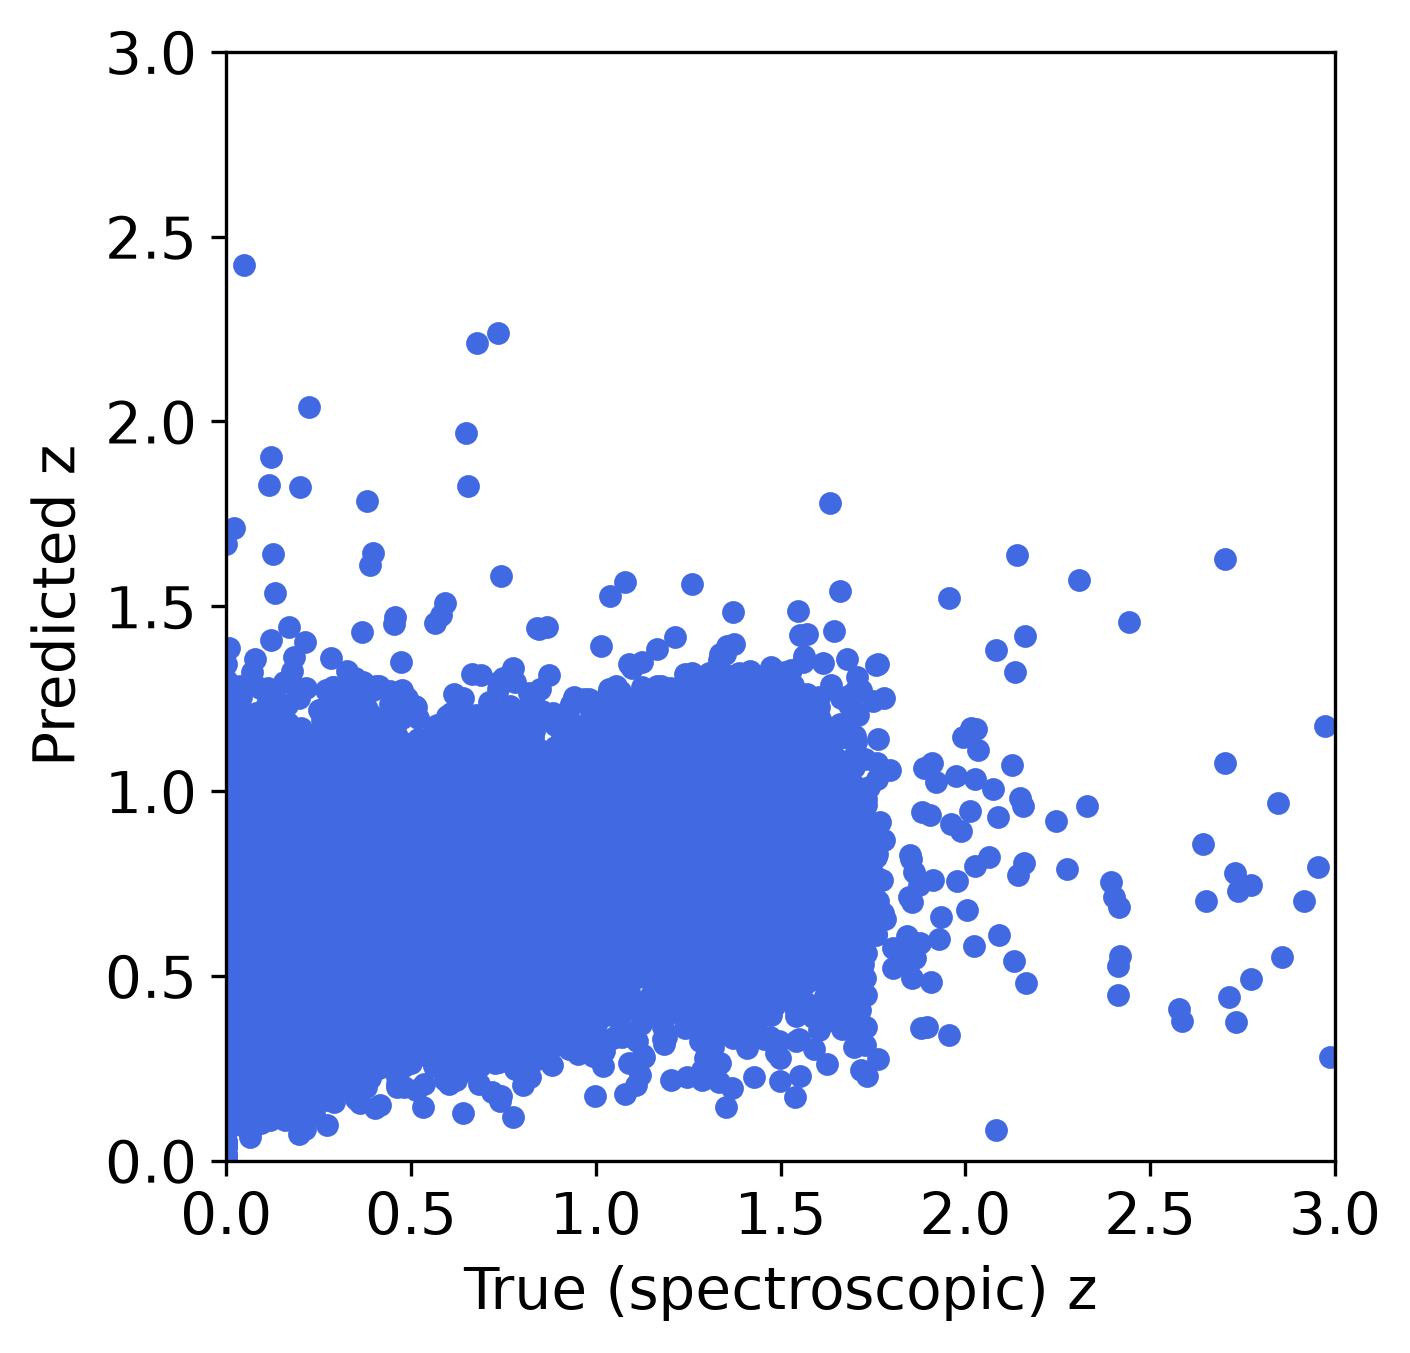

In [41]:
plt.scatter(target,ypred, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

### Se parece al resultado del paper??
- Revisando el paper y la imagen a la que se debiera parecer, la imagen del paper tiene como una relación mucho mas "lineal" (no literalmente), pero más tipo 1 es a 1 y sin tantos outliers como se ven en la figura que se hizo anteriormente.

También es interesante observar la distribución de los valores predichos, para ver cómo siempre tienden a producir una distribución más estrecha. 

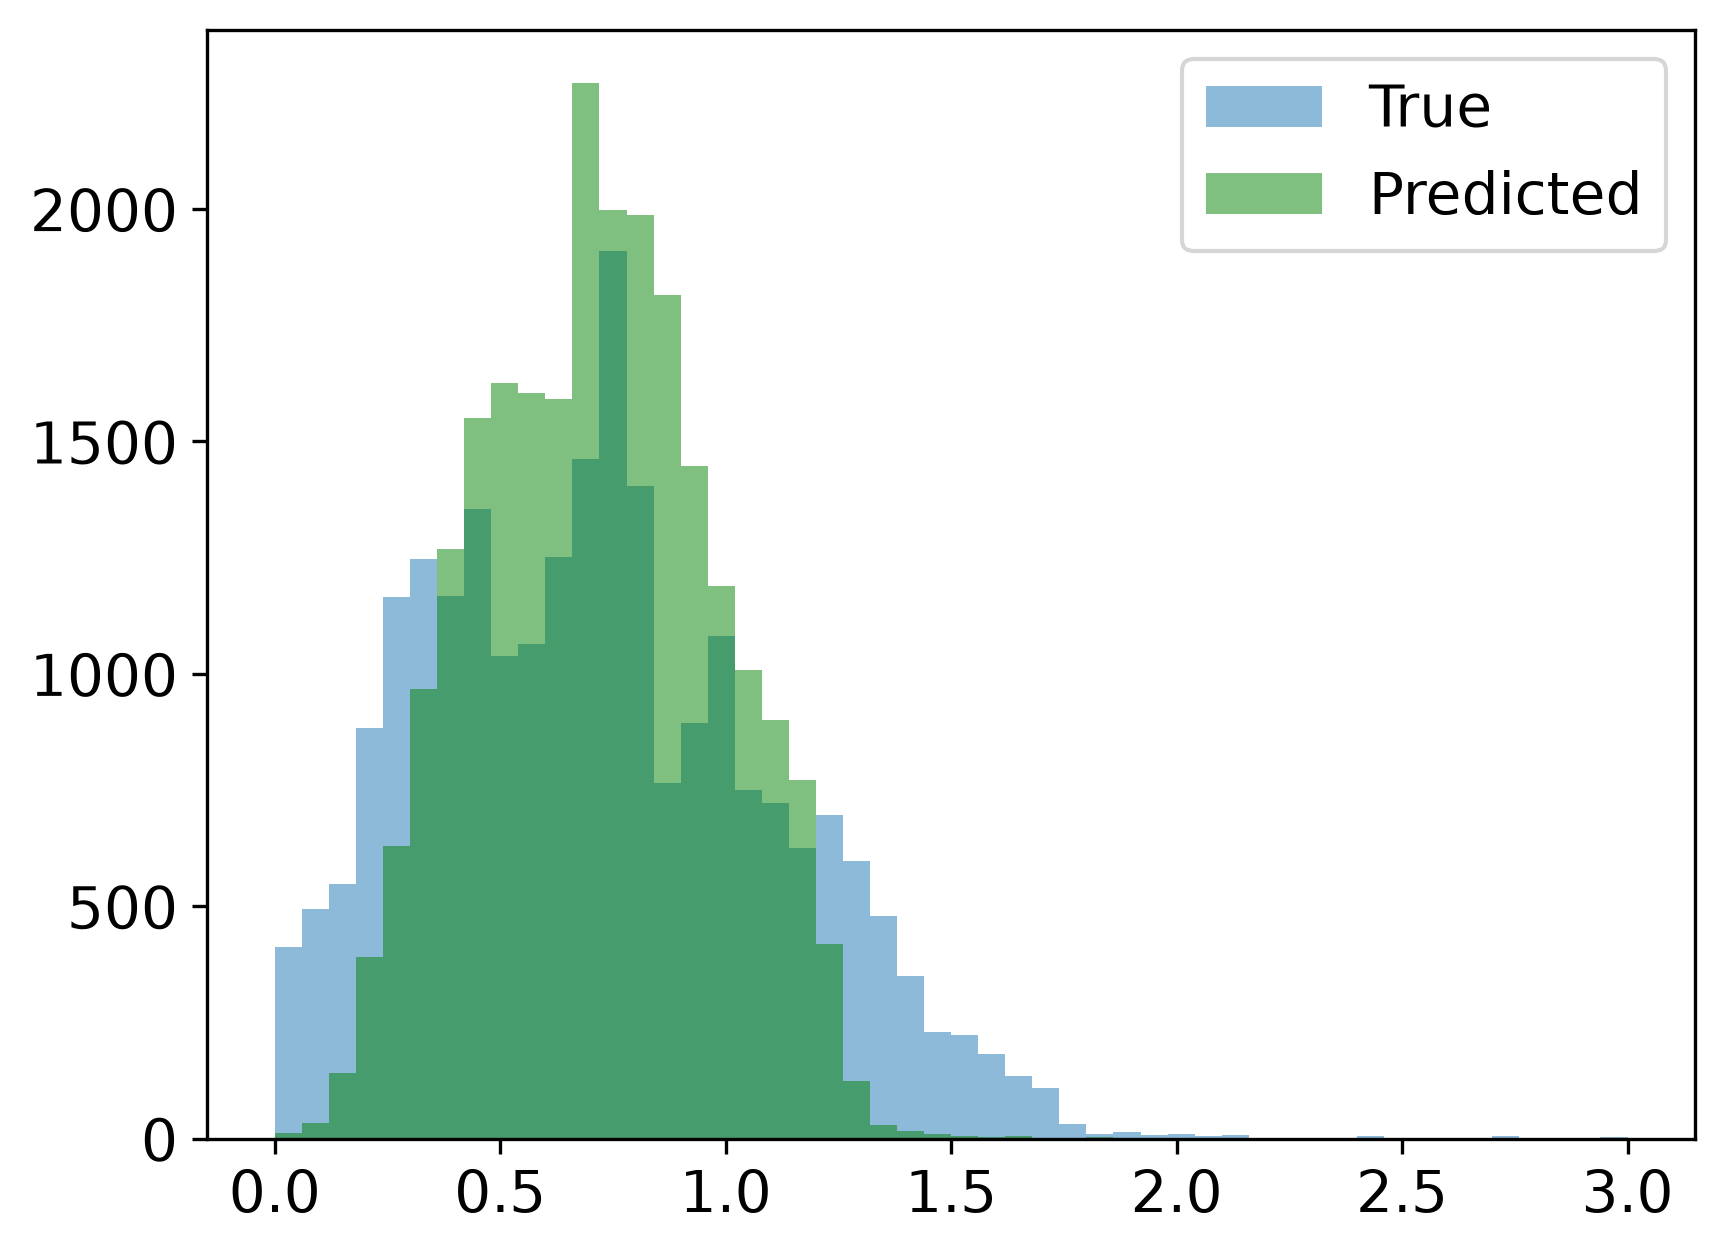

In [42]:
plt.hist(target,bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14);

Ahora calcule las métricas del paper, fracción de outliers $eta$ y $\sigma_{NMAD}$ y compare con los resultados del paper

In [43]:
dz = ypred - target
outliers = np.abs(dz) > 0.15 * (1 + target)
eta = np.mean(outliers)

print(f"Fracción de outliers (eta): {eta:.4f}")

Fracción de outliers (eta): 0.2566


y NMAD

In [44]:
mad = np.median(np.abs(dz) / (1 + target))
sigma_nmad = 1.48 * mad

print(f"Sigma_NMAD: {sigma_nmad:.4f}")

Sigma_NMAD: 0.0745


### Optimicemos los hiperparámetros del modelo

Seleccionemos un subsample de los datos para que se reduzcan los tiempos computacionales

In [45]:
np.random.seed(20)
sel = np.random.choice(range(len(ypred)), 5000, replace = False) #sample sin reemplazo 

In [46]:
len(np.unique(sel))

5000

Y creamos nuestro nuevo dataset más pequeño

In [47]:
seld = features.loc[sel,:]
selt = target[sel]

Chequeemos que la performance del modelo usando todo el set de datos es similar a los obtenidos con nuestro set de datos menor, lo que significaria que el cambio en el tamaño del set no afectará el proceso de optimización

In [48]:
littlescores = cross_validate(model,seld,selt, cv = KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)

In [49]:
littlescores['test_score'].mean(), littlescores['train_score'].mean()

(np.float64(0.27762715338769406), np.float64(0.8763722031531694))

### Estamos listos para optimizar hiperparámetros...cuáles escogemos?



#### Parámetros de árbol

- El número mínimo de instancias en un nodo hoja

- El número mínimo de instancias requerido en un nodo de división

- La profundidad máxima del árbol

- El criterio elegido para decidir si una división "vale la pena", expresado en términos de ganancia de información

#### Parámetros de randomización



- El número de $k < n$ características que se utilizan para construir los árboles

- El resampling (bootstrap) del conjunto de datos (Verdadero o Falso)

#### Parámetros del bosque

El número de árboles en el bosque (n_estimators) se puede ajustar, con el entendimiento general de que más árboles son mejores, pero en algún punto el rendimiento se estabiliza, por lo que se puede encontrar el equilibrio entre tener más árboles y un menor tiempo de ejecución.

Podemos visualizarlos así

In [50]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Implemente `GridSearchCV` o `RandomizedGridSearch()` para los siguientes parámetros y compare los resultados del mejor modelo con los del paper 

- min_impurity_decrease 

- number of trees

- max_leaf_nodes

- min_samples_split

- max_features

In [52]:
%%time
#Toma algunos minutos
parameters = {'min_impurity_decrease':[0.1, 0.5, 0.0], \
              'max_features':[None,4,2], 'n_estimators':[50, 100, 200], 'min_samples_split': [10,20,100], 
              'max_leaf_nodes':[None, 100, 200]}

model = GridSearchCV(estimator=RandomForestRegressor(random_state=10), 
                     param_grid=parameters, 
                     cv=kf, 
                     n_jobs=-1, 
                     verbose=2, 
                     return_train_score=True)

model.fit(seld, selt)

# Imprimimos usando f-strings (tu estilo) en lugar del operador %
print(f"Mejor score (R^2): {model.best_score_:.4f}")
print(f"Mejores parámetros: {model.best_params_}")


Fitting 5 folds for each of 243 candidates, totalling 1215 fits
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=50; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=100; total time=   0.1s
[CV] END max_features=None, max_leaf_nodes=None, min_impurity_decrease=0.1, min_samples_split=10, n_estimators=100; total time=   0

Guardamos el resultado en un dataframe y buscamos el mejor modelo 

In [53]:
scores = pd.DataFrame(model.cv_results_)
scoresCV = scores[['params','mean_test_score','std_test_score','mean_train_score']].sort_values(by = 'mean_test_score', \
                                                    ascending = False)


In [54]:
scoresCV

,params,mean_test_score,std_test_score,mean_train_score
104,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.301286,0.033680,0.651781
101,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.299162,0.034496,0.752954
103,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.298472,0.036001,0.651663
182,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.298117,0.032137,0.725207
181,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.296880,0.030478,0.724445
...,...,...,...,...
81,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.1, 'min_samples_split': 1...",-0.000291,0.000112,-0.000014
201,"{'max_features': 2, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.5, 'min_samples_split': 20...",-0.000291,0.000112,-0.000014
69,"{'max_features': None, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.5, 'min_samples_split':...",-0.000291,0.000112,-0.000014
204,"{'max_features': 2, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.5, 'min_samples_split': 10...",-0.000291,0.000112,-0.000014


### Mejoran los scores?

### Un poco de ingeniería de características

Miraremos otras columnas disponibles del set de datos (Tabla 6 del paper)

In [55]:
mags = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor','subaru_source','cfhtls_source','zquality']]



In [56]:
mags.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356,1,1,2
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000,-99,1,1
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600,1,1,1
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4


In [57]:
mags.shape

(23822, 9)

In [58]:
#zquality - solo usa objetos con medición de redshift de buena calidad

mags = mags[mags['zquality'] >= 3]

mags.shape

(16857, 9)

In [59]:
#selecciona objetos con datos del catálogo cfhtls deep photometric data

mags = mags[mags['cfhtls_source'] == 0]

mags.shape

(10671, 9)

Las mediciones no disponibles están marcadas por -99 o 99 (mientras que los valores típicos están alrededor de 20-25). También eliminamos los datos con mediciones faltantes.

In [60]:
mags = mags[mags > -10].dropna()

In [61]:
mags.shape

(6371, 9)

In [62]:
mags = mags[mags < 90].dropna()

In [63]:
mags.shape

(6307, 9)

Tenemos un dataset con las 6 features originales y 6307 objetos

In [64]:
sel_features = mags[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor']]
sel_features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
1251,24.244393,23.979583,23.522136,22.911041,22.525773,22.329098
1253,24.489104,23.916151,22.923651,21.873752,21.306495,21.251440
1261,24.873959,22.973893,21.465850,20.788420,20.462283,20.413696
1271,24.529042,24.338631,23.891189,23.206102,22.989344,23.112382
1272,23.641180,23.387447,22.975301,22.235199,21.809658,21.559483


Selección del vector de target

In [65]:
sel_target = target[sel_features.index]

**Vuelva a correr el modelo benchmark con estas nuevas características y compare con los resultados anteriores. Puede optimizar nuevamente los hiperparámetros para mejorar aún más el modelo. Compare los valores predichos con los valores reales y concluya respecto a los resultados con la nueva selección de datos.** 

In [67]:
model_new = RandomForestRegressor(random_state=10)
scores_new = cross_validate(model_new, sel_features, sel_target, cv=kf, return_train_score=True, n_jobs=-1)

print(f"Nuevo Train R^2: {scores_new['train_score'].mean():.4f} +/- {scores_new['train_score'].std():.4f}")
print(f"Nuevo Test R^2: {scores_new['test_score'].mean():.4f} +/- {scores_new['test_score'].std():.4f}")

Nuevo Train R^2: 0.9638 +/- 0.0048
Nuevo Test R^2: 0.7457 +/- 0.1036


In [69]:
gs_new = GridSearchCV(estimator=RandomForestRegressor(random_state=10), 
                      param_grid=parameters, 
                      cv=kf, 
                      n_jobs=-1, 
                      verbose=1)

gs_new.fit(sel_features, sel_target)

print(f"Mejor score (R^2) optimizado: {gs_new.best_score_:.4f}")
print(f"Mejores parámetros: {gs_new.best_params_}")

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
Mejor score (R^2) optimizado: 0.7394
Mejores parámetros: {'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 10, 'n_estimators': 100}


(0.0, 3.0)

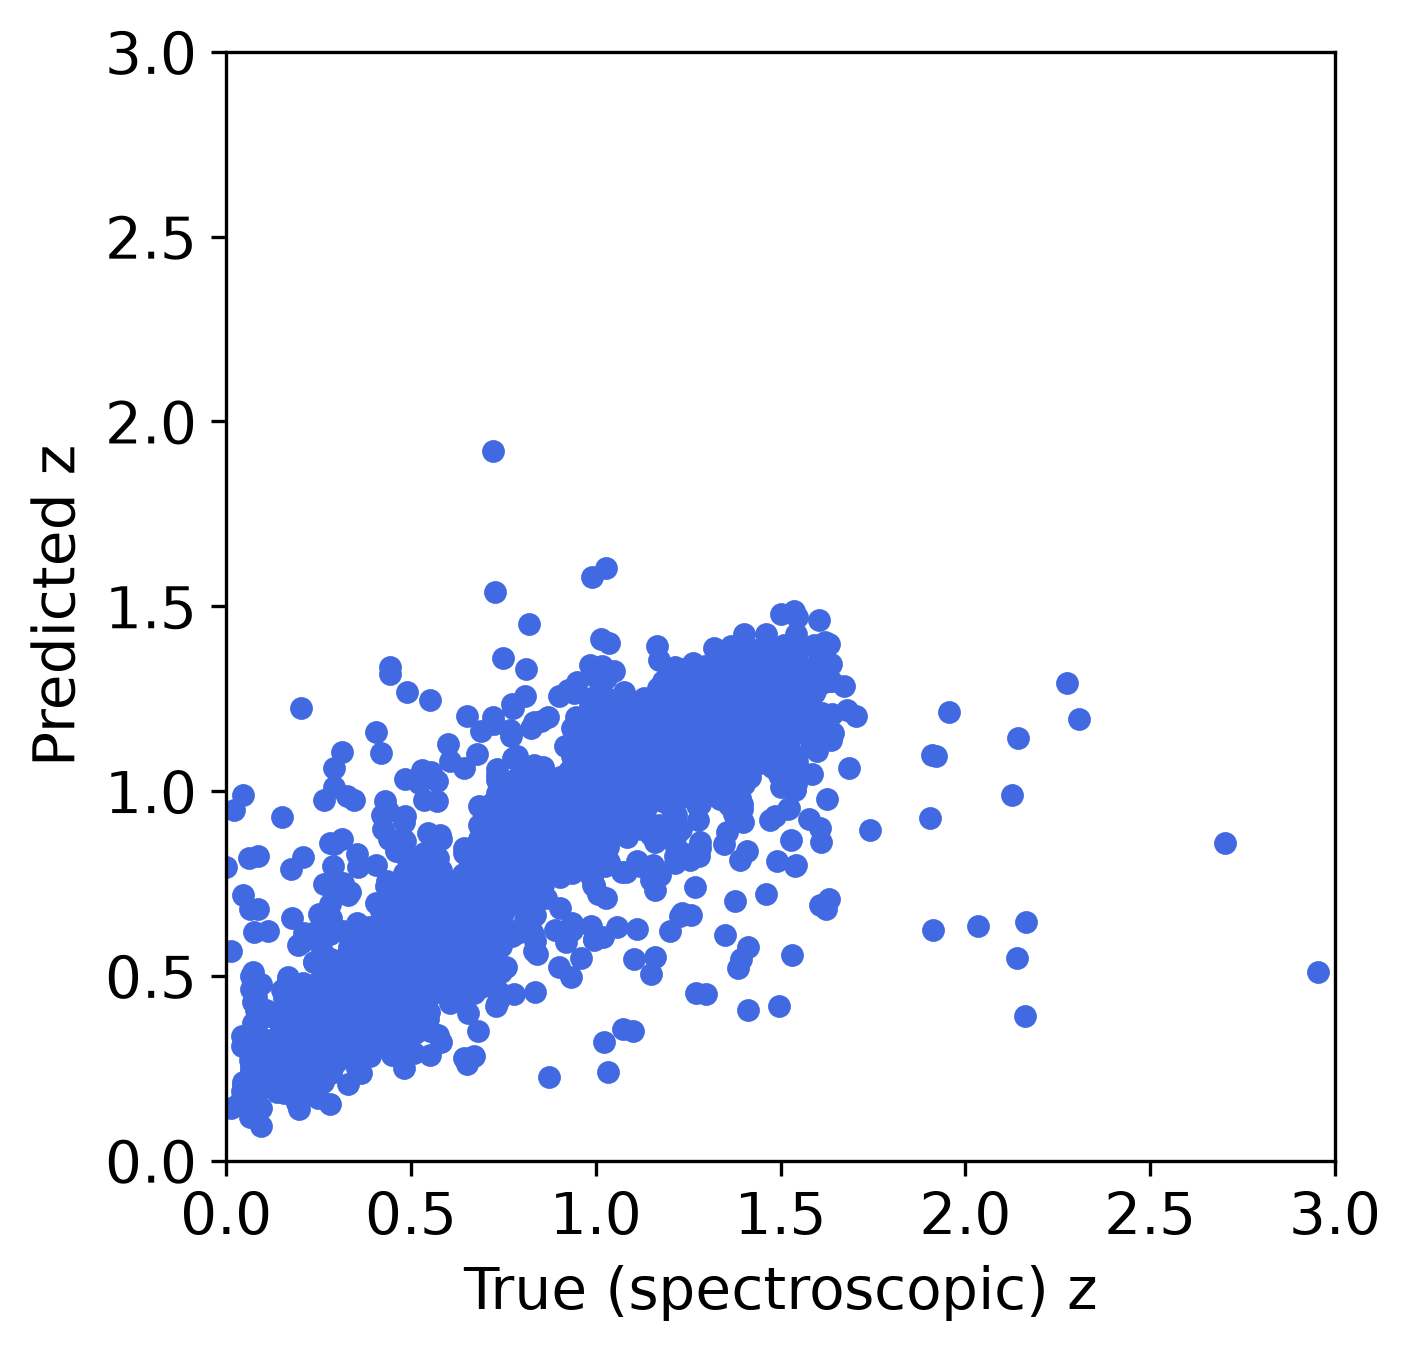

In [72]:

ypred_new = cross_val_predict(gs_new.best_estimator_, sel_features, sel_target, cv=kf, n_jobs=-1)
# para el gráfico nuevo:
plt.scatter(sel_target, ypred_new, s=20, c='royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z', fontsize=14)
plt.axis('square')
plt.xlim(0, 3)
plt.ylim(0, 3)

In [ ]:
delta_z = ypred_new - sel_target
denominador = 1 + sel_target

dispersion_mad = np.median(np.abs(delta_z) / denominador)
sigma_nmad_final = 1.48 * dispersion_mad

total_outliers = np.sum(np.abs(delta_z) > (0.15 * denominador))
eta_final = total_outliers / len(sel_target)

print(f"Nueva Fracción de outliers (η): {eta_final:.4f}")
print(f"Nuevo sigma_NMAD: {sigma_nmad_final:.4f}")

Nueva Fracción de outliers (η): 0.0620
Nuevo sigma_NMAD: 0.0402


### Conclusion: Cómo se compara nuestro modelo con el resultado del paper? 

Revise la sección 7 del paper. Podemos mejorar nuestro modelo aún más? Implemente un nuevo modelo con la mejora identificada



Efectivamente, al leer el paper y revisar la sección 7 encontramos mejoras que cambian drasticamente (de buena forma) el escenario anterior, el codigo a continuación incluye darle al modelo los 5 colores fotométricos y la banda i de referencia:

In [ ]:

sel_features_colors = pd.DataFrame(index=sel_features.index)
sel_features_colors['u-g'] = sel_features['u_apercor'] - sel_features['g_apercor']
sel_features_colors['g-r'] = sel_features['g_apercor'] - sel_features['r_apercor']
sel_features_colors['r-i'] = sel_features['r_apercor'] - sel_features['i_apercor']
sel_features_colors['i-z'] = sel_features['i_apercor'] - sel_features['z_apercor']
sel_features_colors['z-y'] = sel_features['z_apercor'] - sel_features['y_apercor']
sel_features_colors['i_mag'] = sel_features['i_apercor'] 

grid_colors = GridSearchCV(estimator=RandomForestRegressor(random_state=10), 
                           param_grid=parameters, 
                           cv=kf, 
                           n_jobs=-1,
                           verbose=1)
grid_colors.fit(sel_features_colors, sel_target)

print(f"Mejor R^2 usando colores: {grid_colors.best_score_:.4f}")

ypred_colors = cross_val_predict(grid_colors.best_estimator_, sel_features_colors, sel_target, cv=kf, n_jobs=-1)

delta_z_col = ypred_colors - sel_target
denom_col = 1 + sel_target

nmad_colors = 1.48 * np.median(np.abs(delta_z_col) / denom_col)
eta_colors = np.sum(np.abs(delta_z_col) > (0.15 * denom_col)) / len(sel_target)

print(f"Fracción de outliers con colores (η): {eta_colors:.4f}")
print(f"Desviación con colores (σ_NMAD): {nmad_colors:.4f}")

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
Mejor R^2 usando colores: 0.8095
Fracción de outliers con colores (η): 0.0350
Desviación con colores (σ_NMAD): 0.0169


En este notebook comprobamos que limpiar los datos y usar mejores características hace toda la diferencia. 

- El modelo inicial tuvo demasiado overfitting, pero solo con filtrar las observaciones de mala calidad el R2 pasó de 0.30 a 0.74.

- La mejora clave (Sección 7 del paper) fue pasarle al algoritmo los 5 colores fotométricos y la banda $i$ de referencia, en vez de las magnitudes sueltas. Los números finales demuestran claramente la mejora, ya que el R2 subió a 0.8095, los outliers cayeron a 3.5% (eta = 0.0350) y la dispersión bajó a sigma = 0.0169. 

- Tal como propone el paper, entregarle directamente los colores al modelo mejora muchísimo la predicción del redshift. 